# 01 · AI4I 2020 — exploratory analysis (T07)

**Dataset**: AI4I 2020 Predictive Maintenance (UCI #601, Matzka 2020). 10 000 machining records, 5 process
variables, a `failure` label and 5 failure modes (TWF tool wear, HDF heat dissipation, PWF power,
OSF overstrain, RNF random).

**Why we use it**: a labelled, tabular baseline for the Isolation Forest detector (T13) and for SHAP (T22).
The failure modes map onto our fault catalogue (`ai4i.TO_CATALOG`).

Raw data: `python scripts/download_datasets.py ai4i`.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

In [2]:
from roottwin.datasets import ai4i
df = ai4i.load()
print(df.shape); df.head()

(10000, 17)


,udi,product_id,quality,air_temp_k,process_temp_k,rpm,torque_nm,tool_wear_min,failure,TWF,HDF,PWF,OSF,RNF,power_w,temp_diff_k,failure_mode
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0,6951.591,10.5,none
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0,6826.723,10.5,none
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0,7749.388,10.4,none
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0,5927.505,10.4,none
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0,5897.817,10.5,none


## 1. Data quality

In [3]:
print("missing values:", int(df.isna().sum().sum()), "| duplicated ids:", int(df["udi"].duplicated().sum()))
df[list(ai4i.SENSORS) + ["power_w", "temp_diff_k"]].describe().T

missing values: 0 | duplicated ids: 0


,count,mean,std,min,25%,50%,75%,max
air_temp_k,10000.0,300.005,2.000,295.300,298.300,300.100,301.500,304.500
process_temp_k,10000.0,310.006,1.484,305.700,308.800,310.100,311.100,313.800
rpm,10000.0,1538.776,179.284,1168.000,1423.000,1503.000,1612.000,2886.000
torque_nm,10000.0,39.987,9.969,3.800,33.200,40.100,46.800,76.600
tool_wear_min,10000.0,107.951,63.654,0.000,53.000,108.000,162.000,253.000
power_w,10000.0,6279.745,1067.418,1148.441,5561.184,6271.027,7003.003,10469.923
temp_diff_k,10000.0,10.001,1.001,7.600,9.300,9.800,11.000,12.100


## 2. Class imbalance — the key difficulty

failure rate: 3.39%  (339 / 10000)


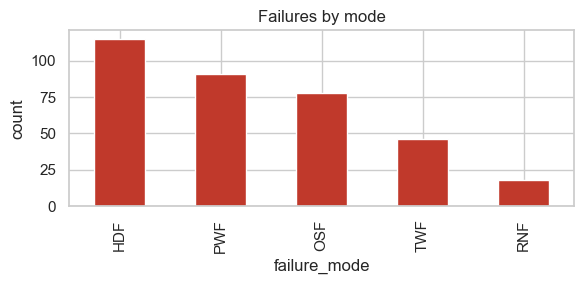

In [4]:
rate = df["failure"].mean()
print(f"failure rate: {rate:.2%}  ({df['failure'].sum()} / {len(df)})")
counts = df.loc[df.failure_mode != "none", "failure_mode"].value_counts()
ax = counts.plot.bar(color="#c0392b", figsize=(6, 3), title="Failures by mode")
ax.set_ylabel("count"); plt.tight_layout()

Only ~3.4 % of records fail. Accuracy is useless here (always predicting "no failure" scores 96.6 %):
we report **precision, recall and F1** (see `docs/KPI.md`) and use stratified splits.

## 3. Distributions: normal vs failure

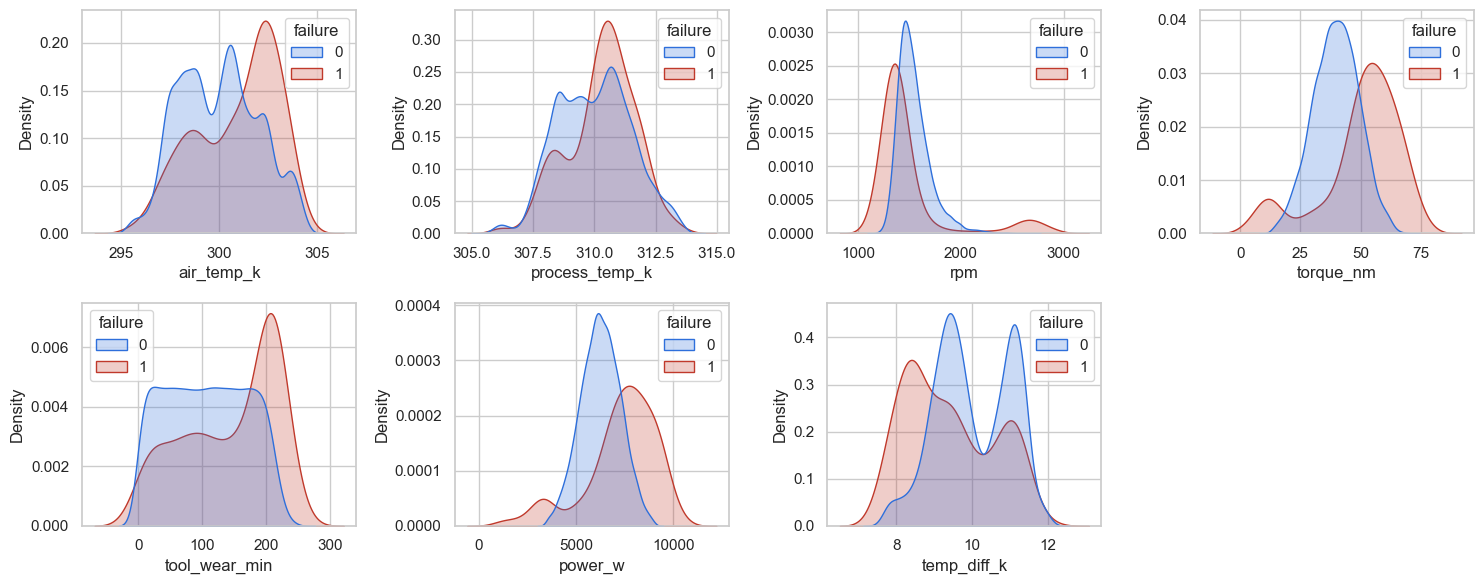

In [5]:
cols = list(ai4i.SENSORS) + ["power_w", "temp_diff_k"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.ravel(), cols):
    sns.kdeplot(data=df, x=c, hue="failure", common_norm=False, fill=True, ax=ax, palette=["#2E6FDB", "#c0392b"])
axes.ravel()[-1].axis("off"); plt.tight_layout()

## 4. Failure modes live in specific regions (physics)

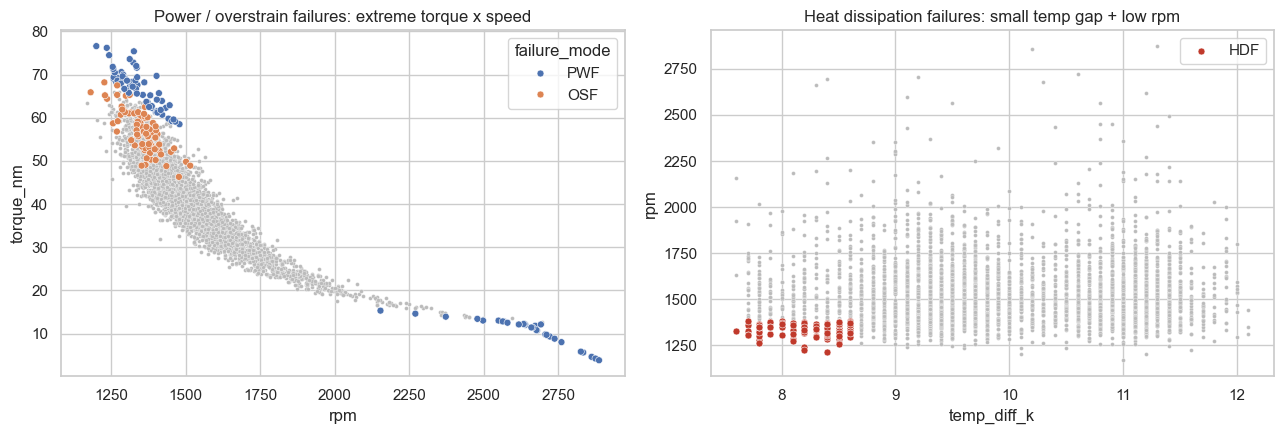

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=df.sample(4000, random_state=0), x="rpm", y="torque_nm", color="#bbb", s=8, ax=axes[0])
sns.scatterplot(data=df[df.failure_mode.isin(["PWF", "OSF"])], x="rpm", y="torque_nm", hue="failure_mode", s=25, ax=axes[0])
axes[0].set_title("Power / overstrain failures: extreme torque x speed")
sns.scatterplot(data=df.sample(4000, random_state=0), x="temp_diff_k", y="rpm", color="#bbb", s=8, ax=axes[1])
sns.scatterplot(data=df[df.failure_mode == "HDF"], x="temp_diff_k", y="rpm", color="#c0392b", s=25, ax=axes[1], label="HDF")
axes[1].set_title("Heat dissipation failures: small temp gap + low rpm"); plt.tight_layout()

## 5. Correlations

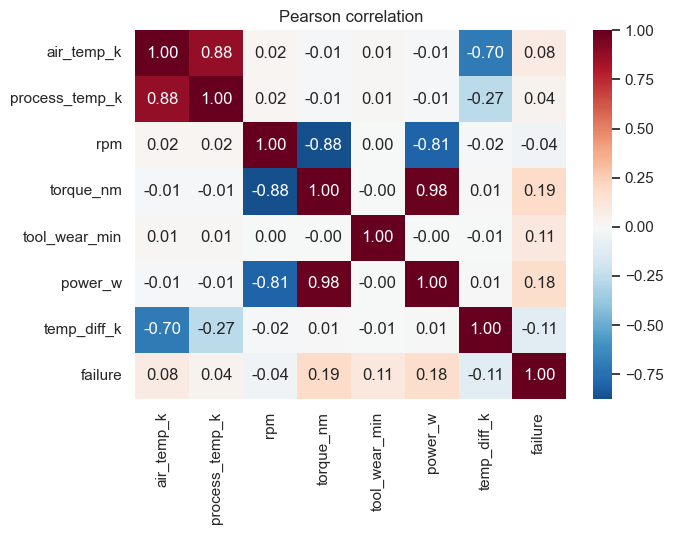

In [7]:
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[cols + ["failure"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Pearson correlation"); plt.tight_layout()

## Takeaways for the detectors

- Heavy imbalance (3.4 %) → precision/recall/F1, stratified split, threshold tuned on recall (KPI: recall ≥ 0.9).
- Engineered features **power** and **temperature gap** separate PWF/HDF far better than raw columns → keep them.
- Tool wear only matters above ~200 min (TWF) → non-linear, tree models / Isolation Forest are a good start.
- RNF (random, 18 cases) is by definition not predictable: exclude it from recall targets.
- Cleaned data: `data/processed/ai4i.parquet`; also in TimescaleDB (`source = 'ai4i'`).